# RIN - experiment 7b.2: controlled-source transfer with diagnostic cues

This notebook is a second controlled-source pass after the first `7b` run.

The first `7b` fixed the main problem of `7a`: noisy automatic anchoring.
But it also showed a subtler issue: even clean manual anchors can still be
**scene-like** rather than **diagnostic**. In that case the signal flows into
the general situation manifold instead of the mechanism that distinguishes the
target from broad distractors.

So this `v2` notebook keeps the same controlled-source regime, but revises the
query cues:

- `primary` queries are meant to discriminate retrieval formulas;
- `control` queries check whether the formulas destroy legitimate broad-topic
  answers;
- source nodes are excluded from the reported retrieval ranking.


In [1]:
import sys
from pathlib import Path


def find_repo_root(marker="requirements.txt"):
    path = Path.cwd()
    for candidate in [path, *path.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"could not find repo root (looked for {marker})")


REPO_ROOT = find_repo_root()
SRC = REPO_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("Repo root:", REPO_ROOT)


Repo root: c:\Users\yaros\BlackSabbitch_repo\RIN


In [2]:
from __future__ import annotations

from collections import Counter
import re

import numpy as np

from embryonic import conceptnet_source
from embryonic.loader import EmbryonicGraphLoader
from embryonic.numberbatch import Numberbatch
from memory.diffuse import diffuse
from memory.graph import MemoryGraph
from memory.pagerank import in_strength_prior, weighted_in_strengths, weighted_out_strengths, weighted_pagerank

try:
    import matplotlib.pyplot as plt
except Exception:
    plt = None

try:
    import pandas as pd
except Exception:
    pd = None


In [3]:
SOURCE_DIR = REPO_ROOT / "source"

CONCEPTNET_DUMP = SOURCE_DIR / "conceptnet-assertions-5.7.0.csv.gz"
ATOMIC_CSV = SOURCE_DIR / "v4_atomic_all_agg.csv"
NUMBERBATCH_FILE = SOURCE_DIR / "numberbatch-en-19.08.txt.gz"

LANGUAGE = "en"
CONCEPTNET_BACKEND = "local_dump"
ATOMIC_FUZZY_LINKING = False
MIN_RELATED_TO_WEIGHT = 2.0

SEED_ENTRIES = [
    "coffee", "caffeine", "beverage", "energy", "water",
    "passport", "boarding pass", "check in", "airport", "travel", "hotel",
    "laptop", "charger", "office",
    "apartment", "wallet", "keys", "cats",
    "umbrella", "outdoor gear",
    "breakfast", "wake up", "espresso",
]

BASE_RADIUS = 3
LIMIT_PER_NODE = 30
MAX_NODES = 10_000

SOURCE_AMPLITUDE = 100.0
EXCLUDE_SOURCE_NODES = True
RUN_OPTIONAL_M5 = False

DIFFUSE_KW = {
    "decay": 0.8,
    "min_propagate_fraction": 0.01,
    "max_steps": 20,
}

TERM_VARIANTS = {
    "boarding pass": ["boarding pass", "boarding_pass"],
    "check in": ["check in", "check_in", "checking in"],
    "check in counter": ["check in counter", "checking in", "check in"],
    "document": ["document", "papers", "paper"],
    "identification": ["identification", "id", "identity card", "passport"],
    "plug": ["plug", "power plug", "electrical plug"],
    "outlet": ["outlet", "wall socket", "socket"],
    "battery": ["battery", "laptop battery"],
    "door": ["door", "front door"],
    "pocket": ["pocket", "coat pocket", "pants pocket"],
    "leave home": ["leave home", "go out", "going out"],
    "carry": ["carry", "take", "bring"],
    "neighbors": ["neighbors", "neighbour", "neighbor"],
    "rent": ["rent", "rental payment"],
    "dwelling": ["dwelling", "home", "residence"],
    "rooms": ["rooms", "room"],
    "itinerary": ["itinerary", "travel plan"],
    "route": ["route", "path", "trip route"],
    "pack suitcase": ["pack suitcase", "suitcase"],
    "wake up": ["wake up", "wake_up"],
    "tired": ["tired", "fatigue", "sleepy"],
    "alert": ["alert", "awake"],
    "stimulant": ["stimulant"],
    "home": ["home", "house", "home life"],
    "trip": ["trip", "travel", "travel planning"],
    "travel": ["travel", "travel planning", "trip"],
}

GRAPH_VARIANTS = [
    {"name": "concept_only", "label": "ConceptNet only", "include_atomic": False},
    {"name": "concept_plus_atomic", "label": "ConceptNet + ATOMIC", "include_atomic": True},
]

METHODS = [
    {"name": "M0_raw", "label": "M0 raw diffusion", "kind": "raw"},
    {"name": "M1_in_strength_05", "label": "M1 raw + in-strength^0.5", "kind": "in_strength", "eta": 0.5},
    {"name": "M2_pagerank_025", "label": "M2 raw + PageRank^0.25", "kind": "pagerank", "eta": 0.25},
    {"name": "M2_pagerank_05", "label": "M2 raw + PageRank^0.5", "kind": "pagerank", "eta": 0.5},
    {"name": "M3_local_leak", "label": "M3 local leak only", "kind": "local_leak", "alpha": 1.0, "beta": 0.05, "gamma": 0.5},
    {"name": "M4_hybrid_pagerank", "label": "M4 local leak + PageRank^0.25", "kind": "hybrid_pagerank", "alpha": 1.0, "beta": 0.05, "gamma": 0.5, "eta": 0.25},
]

if RUN_OPTIONAL_M5:
    METHODS.append({"name": "M5_hybrid_in_strength", "label": "M5 local leak + in-strength^0.5", "kind": "hybrid_in_strength", "alpha": 1.0, "beta": 0.05, "gamma": 0.5, "eta": 0.5})


In [4]:
QUERY_SPECS = [
    {
        "id": "Q1",
        "role": "primary",
        "query": "why coffee gives energy",
        "anchors": ["coffee", "stimulant"],
        "anchor_fallbacks": ["wake up", "energy"],
        "correct": ["caffeine"],
        "distractors": ["beverage", "water"],
        "pairwise": [("caffeine", "beverage")],
    },
    {
        "id": "Q2",
        "role": "primary",
        "query": "what matters at check in",
        "anchors": ["check in counter", "document"],
        "anchor_fallbacks": ["identification", "check in"],
        "correct": ["passport", "boarding pass"],
        "distractors": ["travel", "hotel"],
        "pairwise": [("passport", "travel"), ("boarding pass", "hotel")],
    },
    {
        "id": "Q3",
        "role": "primary",
        "query": "what helps after dead laptop",
        "anchors": ["laptop", "plug"],
        "anchor_fallbacks": ["outlet", "battery", "electricity"],
        "correct": ["charger"],
        "distractors": ["office", "work"],
        "pairwise": [("charger", "office")],
    },
    {
        "id": "Q4",
        "role": "primary",
        "query": "what did i forget at home",
        "anchors": ["door", "pocket"],
        "anchor_fallbacks": ["leave home", "carry"],
        "correct": ["wallet", "keys"],
        "distractors": ["apartment", "cats"],
        "pairwise": [("wallet", "apartment"), ("keys", "cats")],
    },
    {
        "id": "Q7",
        "role": "primary",
        "query": "what to drink in the morning",
        "anchors": ["wake up", "tired"],
        "anchor_fallbacks": ["alert", "morning"],
        "correct": ["espresso", "coffee"],
        "distractors": ["water", "beverage"],
        "pairwise": [("espresso", "water"), ("coffee", "beverage")],
    },
    {
        "id": "Q5",
        "role": "control",
        "query": "tell me about apartment life",
        "anchors": ["neighbors", "rent"],
        "anchor_fallbacks": ["dwelling", "rooms"],
        "correct": ["apartment", "home"],
        "distractors": ["wallet", "keys"],
        "pairwise": [("apartment", "wallet"), ("home", "keys")],
    },
    {
        "id": "Q6",
        "role": "control",
        "query": "tell me about travel planning",
        "anchors": ["itinerary", "hotel"],
        "anchor_fallbacks": ["route", "pack suitcase"],
        "correct": ["travel", "trip"],
        "distractors": ["passport"],
        "pairwise": [("travel", "passport"), ("trip", "passport")],
    },
]


In [5]:
required_paths = [CONCEPTNET_DUMP, NUMBERBATCH_FILE, ATOMIC_CSV]
missing = [path for path in required_paths if not path.exists()]
if missing:
    raise FileNotFoundError("Missing required local source files:\n" + "\n".join(str(path) for path in missing))

print("All required source files are present.")
print(f"ConceptNet dump: {CONCEPTNET_DUMP}")
print(f"ATOMIC CSV:      {ATOMIC_CSV}")
print(f"Numberbatch:     {NUMBERBATCH_FILE}")

print("\nBuilding ConceptNet adjacency index once for reuse...")
adjacency = conceptnet_source.build_language_adjacency(str(CONCEPTNET_DUMP), LANGUAGE)
print(f"Indexed {len(adjacency):,} ConceptNet adjacency lists.")

print("\nLoading Numberbatch...")
numberbatch = Numberbatch()
numberbatch.load(str(NUMBERBATCH_FILE))
print(f"Loaded {len(numberbatch.terms):,} Numberbatch entries.")


All required source files are present.
ConceptNet dump: c:\Users\yaros\BlackSabbitch_repo\RIN\source\conceptnet-assertions-5.7.0.csv.gz
ATOMIC CSV:      c:\Users\yaros\BlackSabbitch_repo\RIN\source\v4_atomic_all_agg.csv
Numberbatch:     c:\Users\yaros\BlackSabbitch_repo\RIN\source\numberbatch-en-19.08.txt.gz

Building ConceptNet adjacency index once for reuse...
Indexed 1,787,373 ConceptNet adjacency lists.

Loading Numberbatch...
Loaded 516,782 Numberbatch entries.


In [6]:
def normalize_text(text: str) -> str:
    text = text.lower().replace("_", " ").strip()
    text = re.sub(r"\s+\([anvr]\)$", "", text)
    text = re.sub(r"\s+", " ", text)
    return text


def concept_term_from_provenance(uri: str) -> str | None:
    parts = uri.split("/")
    if len(parts) > 3 and parts[1] == "c":
        return parts[3].replace("_", " ")
    return None


def node_sort_key(G: MemoryGraph, node_id: int) -> tuple:
    node = G.nodes[node_id]
    content = normalize_text(node.content)
    is_concept = 0 if node.node_kind == "concept" else 1
    has_pos_suffix = 1 if "(" in node.content else 0
    return (is_concept, has_pos_suffix, len(content), node_id)


def build_label_index(G: MemoryGraph) -> dict[str, list[int]]:
    label_index = {}
    for node_id, node in G.nodes.items():
        labels = {normalize_text(node.content)}
        for item in getattr(node, "provenance", []):
            if isinstance(item, str):
                term = concept_term_from_provenance(item)
                if term is not None:
                    labels.add(normalize_text(term))
        for label in labels:
            if label:
                label_index.setdefault(label, []).append(node_id)
    return label_index


def choose_best_node(G: MemoryGraph, node_ids: list[int]) -> int | None:
    if not node_ids:
        return None
    return sorted(set(node_ids), key=lambda node_id: node_sort_key(G, node_id))[0]


def resolve_term(G: MemoryGraph, label_index: dict[str, list[int]], term: str) -> tuple[int | None, str | None]:
    variants = TERM_VARIANTS.get(term, [term])
    variants = [term, *[variant for variant in variants if variant != term]]
    for variant in variants:
        node_ids = label_index.get(normalize_text(variant), [])
        chosen = choose_best_node(G, node_ids)
        if chosen is not None:
            return chosen, variant
    return None, None


def node_label(G: MemoryGraph, node_id: int) -> str:
    node = G.nodes[node_id]
    return f"{node.content} [{node.node_kind}]"


def print_table(rows: list[dict], columns: list[str]) -> None:
    if not rows:
        print("(no rows)")
        return
    widths = {column: max(len(column), *(len(str(row.get(column, ""))) for row in rows)) for column in columns}
    header = " | ".join(column.ljust(widths[column]) for column in columns)
    rule = "-+-".join("-" * widths[column] for column in columns)
    print(header)
    print(rule)
    for row in rows:
        print(" | ".join(str(row.get(column, "")).ljust(widths[column]) for column in columns))


def resolve_manual_anchors(G: MemoryGraph, label_index: dict[str, list[int]], spec: dict) -> dict:
    resolved = []
    missing = []
    trace = []

    for term in spec["anchors"]:
        node_id, resolved_as = resolve_term(G, label_index, term)
        trace.append((term, resolved_as))
        if node_id is None:
            missing.append(term)
        else:
            resolved.append({"term": term, "resolved_as": resolved_as, "node_id": node_id})

    if missing:
        for fallback in spec.get("anchor_fallbacks", []):
            node_id, resolved_as = resolve_term(G, label_index, fallback)
            trace.append((fallback, resolved_as))
            if node_id is not None:
                resolved.append({"term": fallback, "resolved_as": resolved_as, "node_id": node_id})

    seen = set()
    deduped = []
    for item in resolved:
        if item["node_id"] not in seen:
            deduped.append(item)
            seen.add(item["node_id"])

    return {
        "anchor_ids": [item["node_id"] for item in deduped],
        "anchor_labels": [node_label(G, item["node_id"]) for item in deduped],
        "resolved": deduped,
        "missing": missing,
        "trace": trace,
    }


def remove_source_nodes(scores: dict[int, float], source_ids: list[int]) -> dict[int, float]:
    if not EXCLUDE_SOURCE_NODES:
        return dict(scores)
    excluded = set(source_ids)
    return {node_id: score for node_id, score in scores.items() if node_id not in excluded}


def top_k_concepts(G: MemoryGraph, scores: dict[int, float], k: int = 10) -> list[tuple[int, float]]:
    rows = [(node_id, score) for node_id, score in scores.items() if G.nodes[node_id].node_kind == "concept"]
    return sorted(rows, key=lambda item: item[1], reverse=True)[:k]


def format_top_k(G: MemoryGraph, scores: dict[int, float], k: int = 10) -> list[str]:
    return [f"{node_label(G, node_id)} :: {score:.4f}" for node_id, score in top_k_concepts(G, scores, k=k)]


def best_score(scores: dict[int, float], node_ids: list[int]) -> tuple[int | None, float | None]:
    present = [(node_id, scores.get(node_id, 0.0)) for node_id in node_ids]
    if not present:
        return None, None
    return max(present, key=lambda item: item[1])


def method_denominator(node_id: int, method: dict, out_strengths: dict[int, float], priors: dict[str, dict[int, float]]) -> float:
    kind = method["kind"]
    denominator = 1.0
    if kind in {"local_leak", "hybrid_pagerank", "hybrid_in_strength"}:
        denominator *= method["alpha"] + method["beta"] * (out_strengths[node_id] ** method["gamma"])
    if kind in {"in_strength", "hybrid_in_strength"}:
        denominator *= priors["in_strength"][node_id] ** method["eta"]
    if kind in {"pagerank", "hybrid_pagerank"}:
        denominator *= priors["pagerank"][node_id] ** method["eta"]
    return denominator


def apply_method(base_scores: dict[int, float], method: dict, out_strengths: dict[int, float], priors: dict[str, dict[int, float]]) -> dict[int, float]:
    if method["kind"] == "raw":
        return dict(base_scores)
    adjusted = {}
    for node_id, score in base_scores.items():
        denominator = method_denominator(node_id, method, out_strengths, priors)
        adjusted[node_id] = score / denominator if denominator > 0 else score
    return adjusted


def resolve_eval_terms(G: MemoryGraph, label_index: dict[str, list[int]], terms: list[str]) -> tuple[list[dict], list[str]]:
    resolved = []
    missing = []
    for term in terms:
        node_id, resolved_as = resolve_term(G, label_index, term)
        if node_id is None:
            missing.append(term)
        else:
            resolved.append({"term": term, "resolved_as": resolved_as, "node_id": node_id})
    return resolved, missing


In [7]:
def evaluate_query(G: MemoryGraph, label_index: dict[str, list[int]], spec: dict, scores_all: dict[int, float], scores_ex_source: dict[int, float], anchor_info: dict) -> dict:
    resolved_correct, missing_correct = resolve_eval_terms(G, label_index, spec["correct"])
    resolved_distractors, missing_distractors = resolve_eval_terms(G, label_index, spec["distractors"])

    correct_ids = [item["node_id"] for item in resolved_correct]
    distractor_ids = [item["node_id"] for item in resolved_distractors]

    best_correct_id, best_correct_score = best_score(scores_ex_source, correct_ids)
    best_distractor_id, best_distractor_score = best_score(scores_ex_source, distractor_ids)

    solved = None
    margin = None
    if best_correct_score is not None and best_distractor_score is not None:
        solved = best_correct_score > best_distractor_score
        margin = best_correct_score - best_distractor_score

    source_set = set(anchor_info["anchor_ids"])
    pairwise_rows = []
    skipped_pairwise = 0

    for left_term, right_term in spec["pairwise"]:
        left_id, left_resolved = resolve_term(G, label_index, left_term)
        right_id, right_resolved = resolve_term(G, label_index, right_term)
        skipped = False
        passed = None
        if left_id is None or right_id is None:
            passed = None
        elif left_id in source_set or right_id in source_set:
            skipped = True
            skipped_pairwise += 1
        else:
            passed = scores_ex_source.get(left_id, 0.0) > scores_ex_source.get(right_id, 0.0)
        pairwise_rows.append({
            "left_term": left_term,
            "left_resolved": left_resolved,
            "right_term": right_term,
            "right_resolved": right_resolved,
            "passed": passed,
            "skipped": skipped,
        })

    return {
        "id": spec["id"],
        "role": spec["role"],
        "query": spec["query"],
        "anchor_labels": anchor_info["anchor_labels"],
        "anchor_ids": anchor_info["anchor_ids"],
        "anchor_trace": anchor_info["trace"],
        "anchor_missing": anchor_info["missing"],
        "resolved_correct": resolved_correct,
        "resolved_distractors": resolved_distractors,
        "missing_correct": missing_correct,
        "missing_distractors": missing_distractors,
        "best_correct_id": best_correct_id,
        "best_correct_score": best_correct_score,
        "best_distractor_id": best_distractor_id,
        "best_distractor_score": best_distractor_score,
        "solved": solved,
        "margin": margin,
        "pairwise": pairwise_rows,
        "skipped_pairwise": skipped_pairwise,
        "top10_all": format_top_k(G, scores_all, k=10),
        "top10_ex_source": format_top_k(G, scores_ex_source, k=10),
        "top20_ex_source": format_top_k(G, scores_ex_source, k=20),
    }


def summarize_method(results: list[dict]) -> dict:
    summary = {
        "all": {"queries_with_decision": 0, "solved_queries": 0, "pairwise_total": 0, "pairwise_passed": 0, "skipped_pairwise": 0, "total_margin": 0.0},
        "primary": {"queries_with_decision": 0, "solved_queries": 0, "pairwise_total": 0, "pairwise_passed": 0, "skipped_pairwise": 0, "total_margin": 0.0},
        "control": {"queries_with_decision": 0, "solved_queries": 0, "pairwise_total": 0, "pairwise_passed": 0, "skipped_pairwise": 0, "total_margin": 0.0},
    }

    for row in results:
        buckets = [summary["all"], summary[row["role"]]]
        passed_values = [pair["passed"] for pair in row["pairwise"] if pair["passed"] is not None]
        for bucket in buckets:
            if row["solved"] is not None:
                bucket["queries_with_decision"] += 1
                bucket["solved_queries"] += int(bool(row["solved"]))
            bucket["pairwise_total"] += len(passed_values)
            bucket["pairwise_passed"] += sum(1 for value in passed_values if value)
            bucket["skipped_pairwise"] += row["skipped_pairwise"]
            if row["margin"] is not None:
                bucket["total_margin"] += row["margin"]
    return summary


In [8]:
def loader_for_variant(variant: dict) -> EmbryonicGraphLoader:
    return EmbryonicGraphLoader(
        entries=SEED_ENTRIES,
        radius=BASE_RADIUS,
        language=LANGUAGE,
        conceptnet_backend=CONCEPTNET_BACKEND,
        conceptnet_adjacency=adjacency,
        limit_per_node=LIMIT_PER_NODE,
        max_nodes=MAX_NODES,
        min_related_to_weight=MIN_RELATED_TO_WEIGHT,
        include_atomic=variant["include_atomic"],
        atomic_path=str(ATOMIC_CSV) if variant["include_atomic"] else None,
        numberbatch=numberbatch,
        atomic_fuzzy_linking=ATOMIC_FUZZY_LINKING,
    )


def graph_stats(G: MemoryGraph, priors: dict[str, dict[int, float]], strengths: dict[str, dict[int, float]]) -> dict:
    node_kind_counts = Counter(node.node_kind for node in G.nodes.values())
    edge_count = sum(len(G.out_edges(node_id)) for node_id in G.node_ids())
    top_pagerank = [(node_label(G, node_id), priors["pagerank"][node_id]) for node_id in sorted(priors["pagerank"], key=priors["pagerank"].get, reverse=True) if G.nodes[node_id].node_kind == "concept"][:10]
    top_in_strength = [(node_label(G, node_id), strengths["in"][node_id]) for node_id in sorted(strengths["in"], key=strengths["in"].get, reverse=True) if G.nodes[node_id].node_kind == "concept"][:10]
    return {
        "nodes": len(G.nodes),
        "edges": edge_count,
        "concept_nodes": node_kind_counts.get("concept", 0),
        "episode_nodes": node_kind_counts.get("episode", 0),
        "other_kinds": {kind: count for kind, count in node_kind_counts.items() if kind not in {"concept", "episode"}},
        "top_pagerank": top_pagerank,
        "top_in_strength": top_in_strength,
    }


def run_variant(variant: dict) -> dict:
    G = loader_for_variant(variant).load()
    label_index = build_label_index(G)
    priors = {
        "pagerank": weighted_pagerank(G, damping=0.85),
        "in_strength": in_strength_prior(G),
    }
    strengths = {
        "in": weighted_in_strengths(G),
        "out": weighted_out_strengths(G),
    }

    raw_queries = []
    for spec in QUERY_SPECS:
        anchor_info = resolve_manual_anchors(G, label_index, spec)
        source_amplitudes = {node_id: SOURCE_AMPLITUDE for node_id in anchor_info["anchor_ids"]}
        raw_scores = diffuse(G, source_amplitudes, **DIFFUSE_KW) if source_amplitudes else {}
        raw_queries.append({"spec": spec, "anchor_info": anchor_info, "raw_scores": raw_scores})

    method_results = {}
    for method in METHODS:
        query_rows = []
        for item in raw_queries:
            scores_all = apply_method(item["raw_scores"], method, strengths["out"], priors)
            scores_ex_source = remove_source_nodes(scores_all, item["anchor_info"]["anchor_ids"])
            query_rows.append(evaluate_query(G, label_index, item["spec"], scores_all, scores_ex_source, item["anchor_info"]))
        method_results[method["name"]] = {"config": method, "summary": summarize_method(query_rows), "queries": query_rows}

    return {
        "variant": variant,
        "graph": G,
        "label_index": label_index,
        "priors": priors,
        "strengths": strengths,
        "stats": graph_stats(G, priors, strengths),
        "methods": method_results,
    }


In [9]:
runs = {}
for variant in GRAPH_VARIANTS:
    print(f"\n=== Building graph variant: {variant['label']} ===")
    runs[variant['name']] = run_variant(variant)
    stats = runs[variant['name']]['stats']
    print(f"Nodes:         {stats['nodes']:,}")
    print(f"Edges:         {stats['edges']:,}")
    print(f"Concept nodes: {stats['concept_nodes']:,}")
    print(f"Episode nodes: {stats['episode_nodes']:,}")
    if stats['other_kinds']:
        print(f"Other kinds:   {stats['other_kinds']}")
    print("Top PageRank concept hubs:")
    for label, value in stats['top_pagerank']:
        print(f"  {label:<40} {value:.6f}")
    print("Top in-strength concept hubs:")
    for label, value in stats['top_in_strength']:
        print(f"  {label:<40} {value:.2f}")



=== Building graph variant: ConceptNet only ===
Nodes:         10,000
Edges:         13,850
Concept nodes: 10,000
Episode nodes: 0
Top PageRank concept hubs:
  stimulant [concept]                      0.008487
  friend's house [concept]                 0.003996
  town [concept]                           0.003720
  fast food restaurant [concept]           0.003064
  suitcase [concept]                       0.002872
  container [concept]                      0.002815
  city [concept]                           0.002703
  kitchen [concept]                        0.002635
  house [concept]                          0.002578
  thing [concept]                          0.002558
Top in-strength concept hubs:
  desk [concept]                           173.45
  food [concept]                           167.60
  water [concept]                          166.70
  house [concept]                          163.43
  fun [concept]                            161.46
  money [concept]                        

In [10]:
summary_rows = []
for variant_name, bundle in runs.items():
    for method_name, payload in bundle['methods'].items():
        s_all = payload['summary']['all']
        s_primary = payload['summary']['primary']
        s_control = payload['summary']['control']
        summary_rows.append({
            'graph': bundle['variant']['label'],
            'method': method_name,
            'label': payload['config']['label'],
            'primary_pairwise': f"{s_primary['pairwise_passed']}/{s_primary['pairwise_total']}",
            'primary_solved': f"{s_primary['solved_queries']}/{s_primary['queries_with_decision']}",
            'control_pairwise': f"{s_control['pairwise_passed']}/{s_control['pairwise_total']}",
            'control_solved': f"{s_control['solved_queries']}/{s_control['queries_with_decision']}",
            'all_pairwise': f"{s_all['pairwise_passed']}/{s_all['pairwise_total']}",
            'all_solved': f"{s_all['solved_queries']}/{s_all['queries_with_decision']}",
            'skipped': s_all['skipped_pairwise'],
        })

print_table(summary_rows, ['graph', 'method', 'primary_pairwise', 'primary_solved', 'control_pairwise', 'control_solved', 'all_pairwise', 'all_solved', 'skipped'])
if pd is not None:
    display(pd.DataFrame(summary_rows))


graph               | method             | primary_pairwise | primary_solved | control_pairwise | control_solved | all_pairwise | all_solved | skipped
--------------------+--------------------+------------------+----------------+------------------+----------------+--------------+------------+--------
ConceptNet only     | M0_raw             | 1/8              | 1/5            | 2/4              | 1/2            | 3/12         | 2/7        | 0      
ConceptNet only     | M1_in_strength_05  | 1/8              | 1/5            | 2/4              | 1/2            | 3/12         | 2/7        | 0      
ConceptNet only     | M2_pagerank_025    | 1/8              | 1/5            | 2/4              | 1/2            | 3/12         | 2/7        | 0      
ConceptNet only     | M2_pagerank_05     | 1/8              | 1/5            | 2/4              | 1/2            | 3/12         | 2/7        | 0      
ConceptNet only     | M3_local_leak      | 1/8              | 1/5            | 2/4            

In [11]:
for variant_name, bundle in runs.items():
    print(f"\n================ PRIMARY QUERY SUMMARY :: {bundle['variant']['label']} ================")
    for method_name, payload in bundle['methods'].items():
        print(f"\n=== {payload['config']['label']} ===")
        rows = []
        for result in payload['queries']:
            if result['role'] != 'primary':
                continue
            best_correct = node_label(bundle['graph'], result['best_correct_id']) if result['best_correct_id'] is not None else '(missing)'
            best_distractor = node_label(bundle['graph'], result['best_distractor_id']) if result['best_distractor_id'] is not None else '(missing)'
            rows.append({
                'query': result['id'],
                'anchors': ', '.join(result['anchor_labels']),
                'best_correct': best_correct,
                'best_distractor': best_distractor,
                'solved': result['solved'],
                'margin': '' if result['margin'] is None else f"{result['margin']:.4f}",
                'anchor_missing': ', '.join(result['anchor_missing']),
            })
        print_table(rows, ['query', 'anchors', 'best_correct', 'best_distractor', 'solved', 'margin', 'anchor_missing'])



================ PRIMARY QUERY SUMMARY :: ConceptNet only ================

=== M0 raw diffusion ===
query | anchors                                                    | best_correct       | best_distractor     | solved | margin  | anchor_missing
------+------------------------------------------------------------+--------------------+---------------------+--------+---------+---------------
Q1    | coffee [concept], stimulant [concept]                      | caffeine [concept] | beverage [concept]  | True   | 3.9338  |               
Q2    | check in counter [concept], document [concept]             | passport [concept] | travel [concept]    | False  | 0.0000  |               
Q3    | laptop [concept], battery [concept], electricity [concept] | charger [concept]  | office [concept]    | False  | -2.5515 | plug          
Q4    | door [concept], pocket [concept]                           | wallet [concept]   | apartment [concept] | False  | -2.2368 |               
Q7    | wake up [conce

In [12]:
for variant_name, bundle in runs.items():
    print(f"\n================ PRIMARY PAIRWISE :: {bundle['variant']['label']} ================")
    for method_name, payload in bundle['methods'].items():
        print(f"\n=== {payload['config']['label']} ===")
        rows = []
        for result in payload['queries']:
            if result['role'] != 'primary':
                continue
            for pair in result['pairwise']:
                rows.append({
                    'query': result['id'],
                    'left': pair['left_resolved'] or pair['left_term'],
                    'right': pair['right_resolved'] or pair['right_term'],
                    'passed': pair['passed'],
                    'skipped': pair['skipped'],
                })
        print_table(rows, ['query', 'left', 'right', 'passed', 'skipped'])



================ PRIMARY PAIRWISE :: ConceptNet only ================

=== M0 raw diffusion ===
query | left          | right     | passed | skipped
------+---------------+-----------+--------+--------
Q1    | caffeine      | beverage  | True   | False  
Q2    | passport      | travel    | False  | False  
Q2    | boarding pass | hotel     | False  | False  
Q3    | charger       | office    | False  | False  
Q4    | wallet        | apartment | False  | False  
Q4    | keys          | cats      | False  | False  
Q7    | espresso      | water     | False  | False  
Q7    | coffee        | beverage  | False  | False  

=== M1 raw + in-strength^0.5 ===
query | left          | right     | passed | skipped
------+---------------+-----------+--------+--------
Q1    | caffeine      | beverage  | True   | False  
Q2    | passport      | travel    | False  | False  
Q2    | boarding pass | hotel     | False  | False  
Q3    | charger       | office    | False  | False  
Q4    | wallet       

In [13]:
METHODS_TO_INSPECT = ['M0_raw', 'M2_pagerank_025', 'M4_hybrid_pagerank']
for variant_name, bundle in runs.items():
    print(f"\n================ TOP-10 EX SOURCE :: {bundle['variant']['label']} ================")
    for method_name in METHODS_TO_INSPECT:
        payload = bundle['methods'][method_name]
        print(f"\n=== {payload['config']['label']} ===")
        for result in payload['queries']:
            print(f"\n{result['id']} [{result['role']}] :: {result['query']}")
            print(f"Anchors: {', '.join(result['anchor_labels']) or '(none)'}")
            print(f"Anchor trace: {result['anchor_trace']}")
            if result['anchor_missing']:
                print(f"Missing anchors: {', '.join(result['anchor_missing'])}")
            print('Top-10 with sources excluded:')
            for line in result['top10_ex_source']:
                print(f"  {line}")



================ TOP-10 EX SOURCE :: ConceptNet only ================

=== M0 raw diffusion ===

Q1 [primary] :: why coffee gives energy
Anchors: coffee [concept], stimulant [concept]
Anchor trace: [('coffee', 'coffee'), ('stimulant', 'stimulant')]
Top-10 with sources excluded:
  caffeine [concept] :: 6.6478
  served hot [concept] :: 6.0684
  coffee shop [concept] :: 4.7005
  made from coffee beans [concept] :: 3.8375
  can [concept] :: 2.7139
  container [concept] :: 2.7139
  cup [concept] :: 2.7139
  internet cafe [concept] :: 2.7139
  office [concept] :: 2.7139
  caffein [concept] :: 2.7139

Q2 [primary] :: what matters at check in
Anchors: check in counter [concept], document [concept]
Anchor trace: [('check in counter', 'check in counter'), ('document', 'document')]
Top-10 with sources excluded:
  airport [concept] :: 19.6415
  checking in [concept] :: 17.0096
  suitcase [concept] :: 15.7132
  checking out [concept] :: 13.8866
  carrying clothes [concept] :: 6.7365
  check in [co

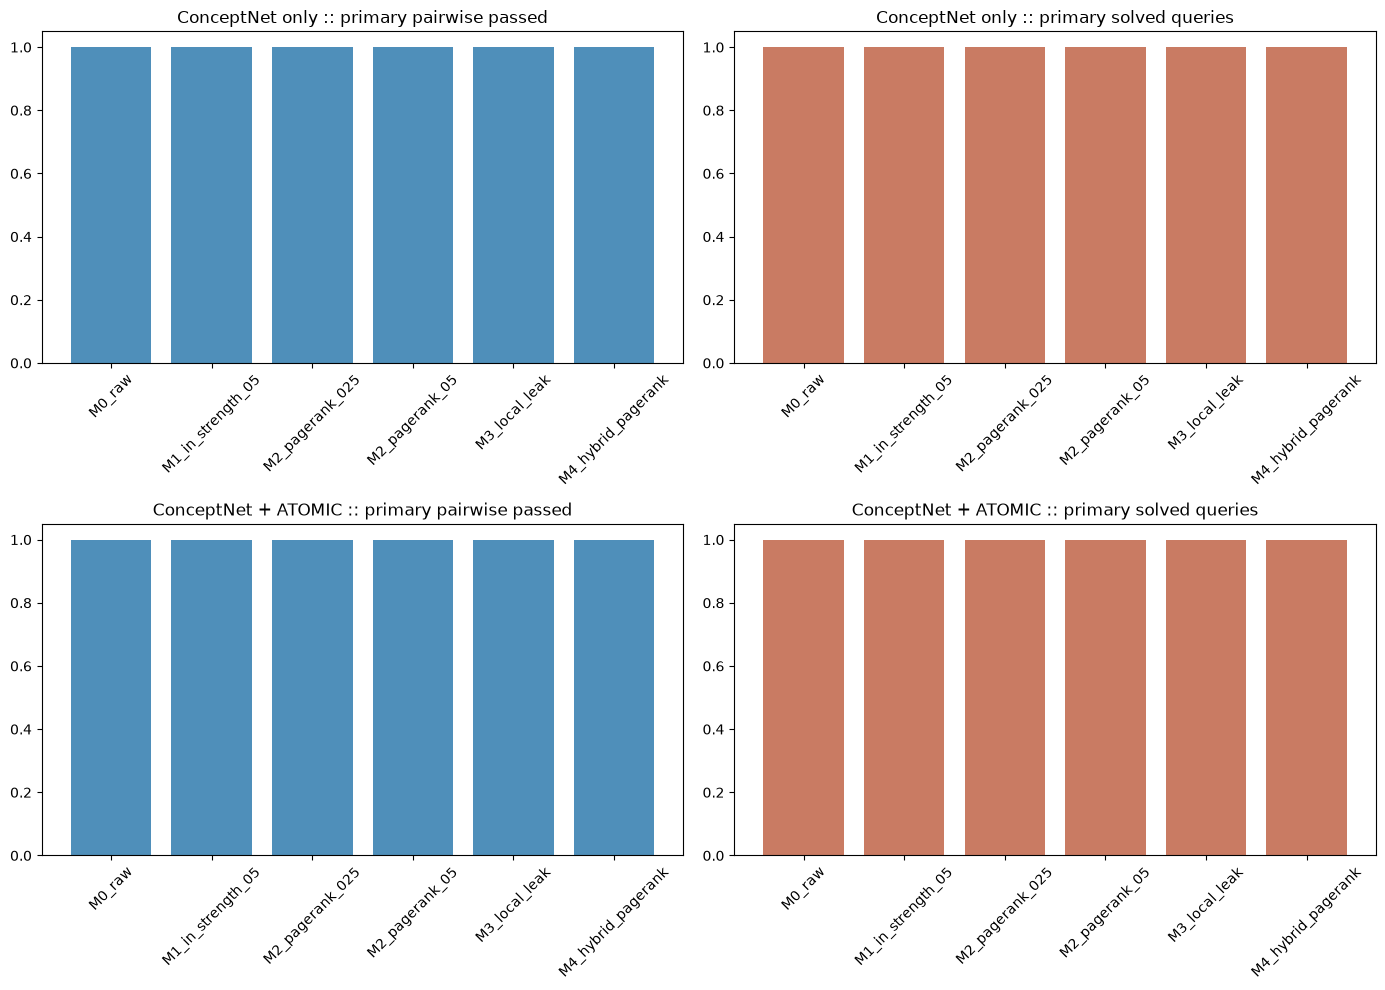

In [14]:
if plt is not None:
    fig, axes = plt.subplots(len(runs), 2, figsize=(14, 5 * max(1, len(runs))))
    if len(runs) == 1:
        axes = [axes]
    for row_idx, (variant_name, bundle) in enumerate(runs.items()):
        method_names = list(bundle['methods'].keys())
        pairwise_passed = [bundle['methods'][name]['summary']['primary']['pairwise_passed'] for name in method_names]
        solved_queries = [bundle['methods'][name]['summary']['primary']['solved_queries'] for name in method_names]
        axes[row_idx][0].bar(method_names, pairwise_passed, color='#4f8fba')
        axes[row_idx][0].set_title(f"{bundle['variant']['label']} :: primary pairwise passed")
        axes[row_idx][0].tick_params(axis='x', rotation=45)
        axes[row_idx][1].bar(method_names, solved_queries, color='#c97b63')
        axes[row_idx][1].set_title(f"{bundle['variant']['label']} :: primary solved queries")
        axes[row_idx][1].tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print('matplotlib unavailable; skipping bar charts.')


## Interpretation checklist

When reading the `v2` output, answer these in order:

1. Did the revised cues finally move the signal into the target mechanism rather than the surrounding scene?
2. On the `primary` queries, do the methods now differ by discrete pairwise outcomes, not only by scale?
3. Does the hybrid help beyond pure PageRank, or does the local leak term still add nothing transferable?
4. Do the `control` queries remain semantically broad, or does the correction over-narrow them?
5. Does ATOMIC help, hurt, or mostly leave the concept-level ordering unchanged?
